# 2 - Predictive models

Target: **High Profit** = the profit of the sale line is above the median (120). Yes / No.

Classification: Logistic Regression, Decision Tree, Random Forest, SVM.
Regression: Linear Regression to predict the profit value.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, r2_score, mean_absolute_error

df = pd.read_csv("../data/cleaned/sales_model.csv", keep_default_na=False, na_values=[""])
df["High Profit"].value_counts()

High Profit
No     13568
Yes    12829
Name: count, dtype: int64

## Prepare the data
No Total or Profit in the inputs, only things we know before the sale. Quantity is capped at the 99th percentile (outliers).

In [2]:
df["Quantity"] = df["Quantity"].clip(upper=df["Quantity"].quantile(.99))

num_cols = ["Quantity", "Unit Price", "Tax Rate", "Lead Time Days", "Typical Weight Per Unit", "Month"]
cat_cols = ["Package", "Color", "Size", "Brand", "Is Chiller Stock", "Buying Group", "Category",
            "State Province", "Weekday"]

X = pd.get_dummies(df[num_cols + cat_cols], columns=cat_cols, drop_first=True).astype(float)
y = (df["High Profit"] == "Yes").astype(int)
X.shape

(26397, 74)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print(len(X_train), len(X_test))

21117 5280


## Train the models

In [4]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": SVC(),
}
scaled = ["Logistic Regression", "SVM"]

results = []
preds = {}
for name, model in models.items():
    if name in scaled:
        model.fit(X_train_s, y_train)
        p = model.predict(X_test_s)
    else:
        model.fit(X_train, y_train)
        p = model.predict(X_test)
    preds[name] = p
    acc = accuracy_score(y_test, p)
    results.append({"Model": name, "Accuracy": round(acc, 4)})
    print(name, round(acc * 100, 2), "%")

Logistic Regression 95.25 %
Decision Tree 99.3 %


Random Forest 99.6 %


SVM 88.88 %


## Confusion matrix

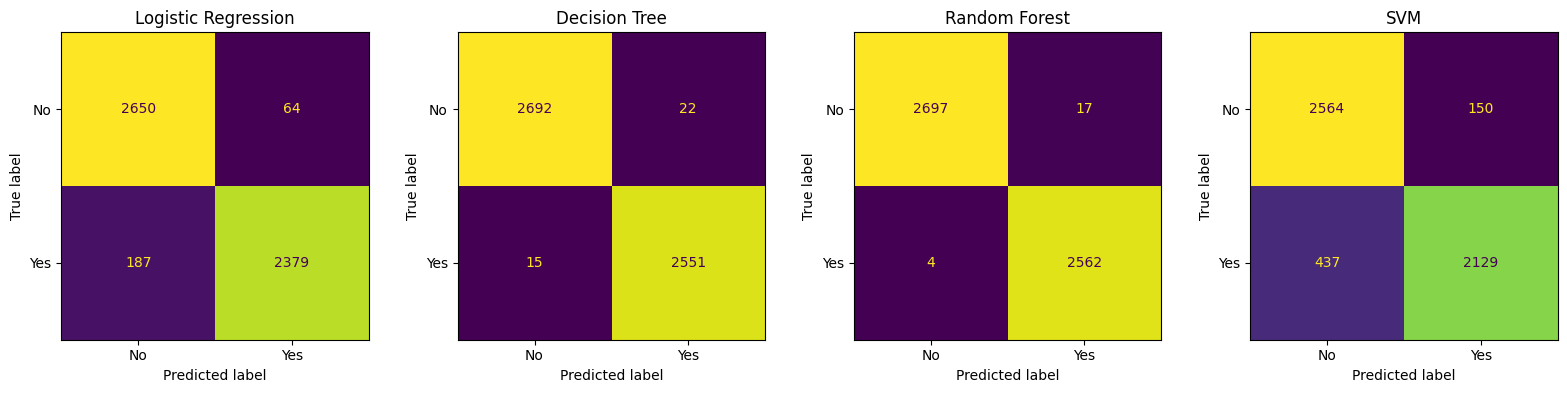

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["No", "Yes"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("../images/charts/confusion_matrix.png", bbox_inches="tight")
plt.show()

## Linear Regression (profit value)

In [6]:
lin = LinearRegression()
lin.fit(X_train, df.loc[X_train.index, "Profit"])
p = lin.predict(X_test)
actual = df.loc[X_test.index, "Profit"]
r2 = r2_score(actual, p)
print("R2:", round(r2, 3))
print("MAE:", round(mean_absolute_error(actual, p), 1))
results.append({"Model": "Linear Regression", "Accuracy": None, "R2": round(r2, 4)})

R2: 0.699
MAE: 195.9


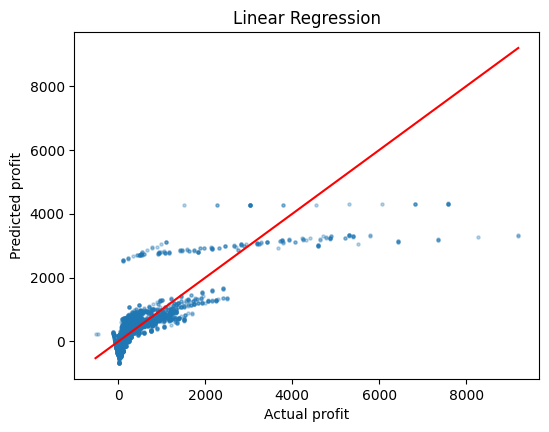

In [7]:
plt.figure(figsize=(6, 4.5))
plt.scatter(actual, p, s=5, alpha=.3)
plt.plot([actual.min(), actual.max()], [actual.min(), actual.max()], color="red")
plt.xlabel("Actual profit")
plt.ylabel("Predicted profit")
plt.title("Linear Regression")
plt.show()

## Compare

In [8]:
res = pd.DataFrame(results)
res

,Model,Accuracy,R2
0,Logistic Regression,0.9525,NaN
1,Decision Tree,0.9930,NaN
2,Random Forest,0.9960,NaN
3,SVM,0.8888,NaN
4,Linear Regression,NaN,0.6987


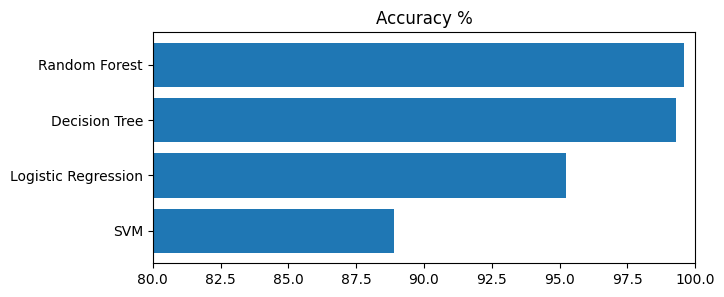

In [9]:
r = res.dropna(subset=["Accuracy"]).sort_values("Accuracy")
plt.figure(figsize=(7, 3))
plt.barh(r["Model"], r["Accuracy"] * 100)
plt.xlim(80, 100)
plt.title("Accuracy %")
plt.savefig("../images/charts/accuracy.png", bbox_inches="tight")
plt.show()

## What matters most (Random Forest)

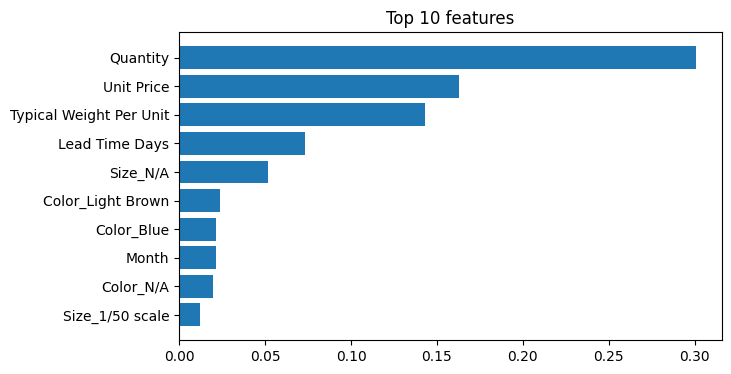

In [10]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).nlargest(10).sort_values()
plt.figure(figsize=(7, 4))
plt.barh(imp.index, imp)
plt.title("Top 10 features")
plt.savefig("../images/charts/features.png", bbox_inches="tight")
plt.show()

## Save for Power BI

In [11]:
res.to_csv("../models/model_results.csv", index=False)

rf = models["Random Forest"]
out = df.loc[X_test.index, ["Sale Key", "Description", "Package", "Buying Group", "State Province",
                            "Quantity", "Unit Price", "Profit", "High Profit"]].copy()
out["Predicted"] = pd.Series(rf.predict(X_test), index=X_test.index).map({1: "Yes", 0: "No"})
out["Probability"] = rf.predict_proba(X_test)[:, 1].round(3)
out["Correct"] = (out["Predicted"] == out["High Profit"]).map({True: "Yes", False: "No"})
out.to_csv("../models/predictions.csv", index=False)

cm = confusion_matrix(y_test, rf.predict(X_test))
pd.DataFrame({"Actual": ["No", "No", "Yes", "Yes"], "Predicted": ["No", "Yes", "No", "Yes"],
              "Count": cm.ravel()}).to_csv("../models/confusion_matrix.csv", index=False)
imp.sort_values(ascending=False).rename("Importance").to_csv("../models/feature_importance.csv", index_label="Feature")
out["Correct"].value_counts()

Correct
Yes    5259
No       21
Name: count, dtype: int64

## Result

Random Forest is the best one, so I use it in the dashboard.
Accuracy is very high because profit depends mostly on quantity and unit price, and the model gets them as inputs.
SVM is the weakest and the slowest.